# C3: model parameters, training and experiments

PP1 notebook 1 of 2. Explain what was trained, inspect the actual runs, and separate measured results from experiments still needed. Continue with [evaluation](02_model_progress_and_evaluation.ipynb).

In [1]:
from pathlib import Path
import sys
# Works when launched from the repository root, vision_oracle, or this folder.
candidates = [p / suffix for p in [Path.cwd(), *Path.cwd().parents]
              for suffix in ('', 'notebooks/pp1', 'vision_oracle/notebooks/pp1')]
HERE = next((p.resolve() for p in candidates if (p/'pp1_evidence.py').exists()), None)
if HERE is None:
    raise FileNotFoundError('Open from the repository or the pp1 notebook folder')
sys.path.insert(0, str(HERE))
from pp1_evidence import *
from IPython.display import display, Markdown
B = load_bundle(HERE)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
display(Markdown('**Mode: saved evidence / CPU only. No model downloads, training, or inference.**'))
print('Verified bundle checksum. Source files:', len(B['provenance']))


**Mode: saved evidence / CPU only. No model downloads, training, or inference.**

Verified bundle checksum. Source files: 41


## 1. Parameters versus hyperparameters
**Parameters** are learned numbers: pretrained weights and trained adapter matrices. **Hyperparameters** are choices made before training: learning rate, rank, dropout, batch size and schedule. **Inference settings** include prompt, resolution and decision threshold; changing them can change results without training.

,component,layers,hidden/embedding size,attention heads
0,Language transformer,28,1536,12
1,Vision transformer,32,1280,16


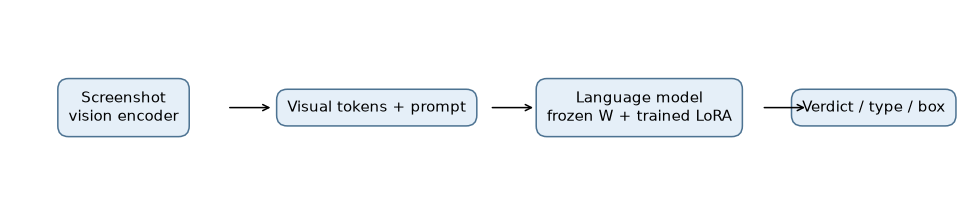

Vocabulary: 151936 | configured context: 32768


In [2]:
cfg = B['base_config']
display(pd.DataFrame([
    ['Language transformer', cfg['num_hidden_layers'], cfg['hidden_size'], cfg['num_attention_heads']],
    ['Vision transformer', cfg['vision_config']['depth'], cfg['vision_config']['embed_dim'], cfg['vision_config']['num_heads']]
], columns=['component','layers','hidden/embedding size','attention heads']))
fig, ax = plt.subplots(figsize=(11, 2.3))
for x, label in [(0.12,'Screenshot\nvision encoder'), (.39,'Visual tokens + prompt'), (.67,'Language model\nfrozen W + trained LoRA'), (.92,'Verdict / type / box')]:
    ax.text(x, .5, label, ha='center', va='center', transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=.7', facecolor='#e5eff8', edgecolor='#4d7392'))
for x in [.23,.51,.8]: ax.annotate('', xy=(x+.05,.5), xytext=(x,.5), xycoords='axes fraction', arrowprops=dict(arrowstyle='->'))
ax.axis('off'); plt.show()
print('Vocabulary:', cfg['vocab_size'], '| configured context:', cfg['max_position_embeddings'])


## 2. What LoRA actually changes
$W_{effective}=W_0+(\alpha/r)BA$. The pretrained matrix $W_0$ stays frozen; $A$ and $B$ are trained. For a matrix with dimensions $d_{out}\times d_{in}$, adapter capacity is $r(d_{in}+d_{out})$. QLoRA uses a quantized base during training. Stored adapter dtype and training compute dtype are different concepts.

,rank,alpha,dropout,adapter_parameters,tensors,vision_tensors,stored_dtype
run,,,,,,,
v1_stage1,16,32,0.00,18464768,392,0,F32
v1_step246,16,32,0.00,18464768,392,0,F32
v2_checkpoint-173,16,32,0.05,18464768,392,0,F32
v2_epoch2,16,32,0.05,18464768,392,0,F32


**2,208,985,600 stored base parameters + 18,464,768 adapter parameters.** The adapter is 0.829% of the combined count; this is added trainable capacity.

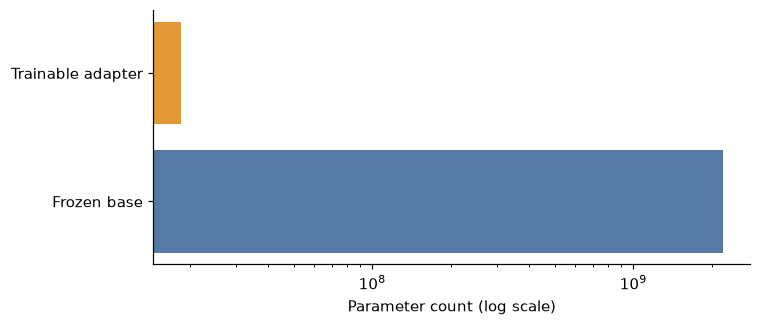

Adapted modules: down_proj, gate_proj, k_proj, o_proj, q_proj, up_proj, v_proj


In [3]:
models = B['models']
rows = []
for m in models:
    c, t = m['config'], m['tensors']
    rows.append(dict(run=m['name'], rank=c['r'], alpha=c['lora_alpha'], dropout=c['lora_dropout'],
        adapter_parameters=m['parameters'], tensors=len(t),
        vision_tensors=sum('visual' in k or 'vision' in k for k in t),
        stored_dtype=','.join(sorted({v['dtype'] for v in t.values()}))))
display(pd.DataFrame(rows).set_index('run'))
base, adapter = B['base_parameters'], models[0]['parameters']
display(Markdown(f'**{base:,} stored base parameters + {adapter:,} adapter parameters.** '
                 f'The adapter is {adapter/(base+adapter):.3%} of the combined count; this is added trainable capacity.'))
fig, ax = plt.subplots(figsize=(7,3))
ax.barh(['Frozen base','Trainable adapter'], [base,adapter], color=['#547aa5','#e39838'])
ax.set_xscale('log'); ax.set_xlabel('Parameter count (log scale)'); plt.show()
print('Adapted modules:', ', '.join(sorted(models[0]['config']['target_modules'])))


## 3. Actual training recipes
| Setting | Meaning and trade-off |
|---|---|
| Learning rate | Update size; too large can destabilize learning, too small may learn too slowly. |
| Rank r | Number of low-rank directions; controls adapter capacity and parameter cost. |
| Alpha | Scales the adapter update by alpha/r; it is not the learning rate. |
| Dropout | Training-time regularization; larger values are not automatically better. |
| Batch / accumulation | Microbatch times accumulation times device count gives effective batch. |
| Epochs / steps | Dataset passes / optimizer updates; affect training exposure and cost. |
| Warmup / scheduler | How learning rate rises initially and changes during the run. |
| Cutoff / image pixels | Text and visual input budgets; can remove useful evidence if too small. |

The saved YAML files record intended settings. Trainer state records completed steps. These runs change several factors together, so they are historical recipe comparisons, not controlled learning-rate experiments.

In [4]:
def yaml_scalar(text, key):
    for line in text.splitlines():
        if line.startswith(key+':'): return line.split(':',1)[1].split('#',1)[0].strip()
    return 'not recorded'
config_names = ['qwen2vl_lora_sft_c3.yaml','qwen2vl_lora_sft_c3_boosted.yaml',
                'qwen2vl_lora_c3_v2.yaml','qwen2vl_lora_c3_v2_epoch2.yaml']
keys = ['dataset','learning_rate','lora_dropout','per_device_train_batch_size',
        'gradient_accumulation_steps','cutoff_len','image_max_pixels','num_train_epochs',
        'warmup_steps','lr_scheduler_type','optim','adapter_name_or_path']
recipes = pd.DataFrame({m['name']: {k:yaml_scalar(B['training_configs'][f],k) for k in keys}
                       for m,f in zip(models,config_names)})
display(recipes)
display(pd.DataFrame([dict(run=m['name'], completed_steps=m['state']['global_step'],
                         completed_epoch=m['state']['epoch'], planned_steps=m['state'].get('max_steps'),
                         eval_loss_points=sum('eval_loss' in x for x in m['state']['log_history'])) for m in models]))
print('Original v2 log excerpts:')
print('\n'.join(B['v2_log_excerpt']))


,v1_stage1,v1_step246,v2_checkpoint-173,v2_epoch2
dataset,c3_train,c3_train_boosted,c3v2_train,c3v2_train
learning_rate,1.0e-4,5.0e-5,1.0e-4,5.0e-5
lora_dropout,not recorded,not recorded,0.05,0.05
per_device_train_batch_size,1,1,1,1
gradient_accumulation_steps,8,8,8,8
cutoff_len,1024,1024,1024,1024
image_max_pixels,262144,262144,262144,262144
num_train_epochs,2.0,2.0,3.0,1.0
warmup_steps,25,15,26,0
lr_scheduler_type,cosine,cosine,cosine,cosine


,run,completed_steps,completed_epoch,planned_steps,eval_loss_points
0,v1_stage1,368,2.0,368,0
1,v1_step246,246,2.0,246,0
2,v2_checkpoint-173,173,1.0,346,0
3,v2_epoch2,173,1.0,173,0


Original v2 log excerpts:
[INFO|2026-10-20 16:12:40] llamafactory.model.adapter:144 >> Upcasting trainable params to float32.
[INFO|2026-10-20 16:12:41] llamafactory.model.loader:144 >> trainable params: 18,464,768 || all params: 2,227,450,368 || trainable%: 0.8290
[INFO|trainer.py:1605] 2026-10-20 16:12:41,854 >>   Num examples = 1,377
[INFO|trainer.py:1606] 2026-10-20 16:12:41,854 >>   Num Epochs = 2
[INFO|trainer.py:1613] 2026-10-20 16:12:41,854 >>   Total optimization steps = 346
[INFO|trainer.py:1614] 2026-10-20 16:12:41,858 >>   Number of trainable parameters = 18,464,768
RuntimeError: CUDA error: out of memory
RuntimeError: CUDA error: out of memory


### Provenance conflict and training lineage
The archived v2 YAML says three epochs, while the actual run log/state describes a two-epoch plan. Do not present the YAML alone as the executed configuration. The saved v2 checkpoint ends at epoch one. The additional epoch loads that adapter into a new training run; a full optimizer-state resume is not demonstrated.

Lineage: base → v1 stage 1 → v1 boosted stage 2; separately, base → v2 checkpoint 173 → v2 additional epoch. v2 changes filtered data membership, compact targets and dropout as well as training history.

## 4. Logged loss and learning rate
Read each run separately. Lower token loss across different target formats/data is not evidence of higher defect accuracy. No validation-loss series is available in these trainer states; checkpoint evaluation comes later.

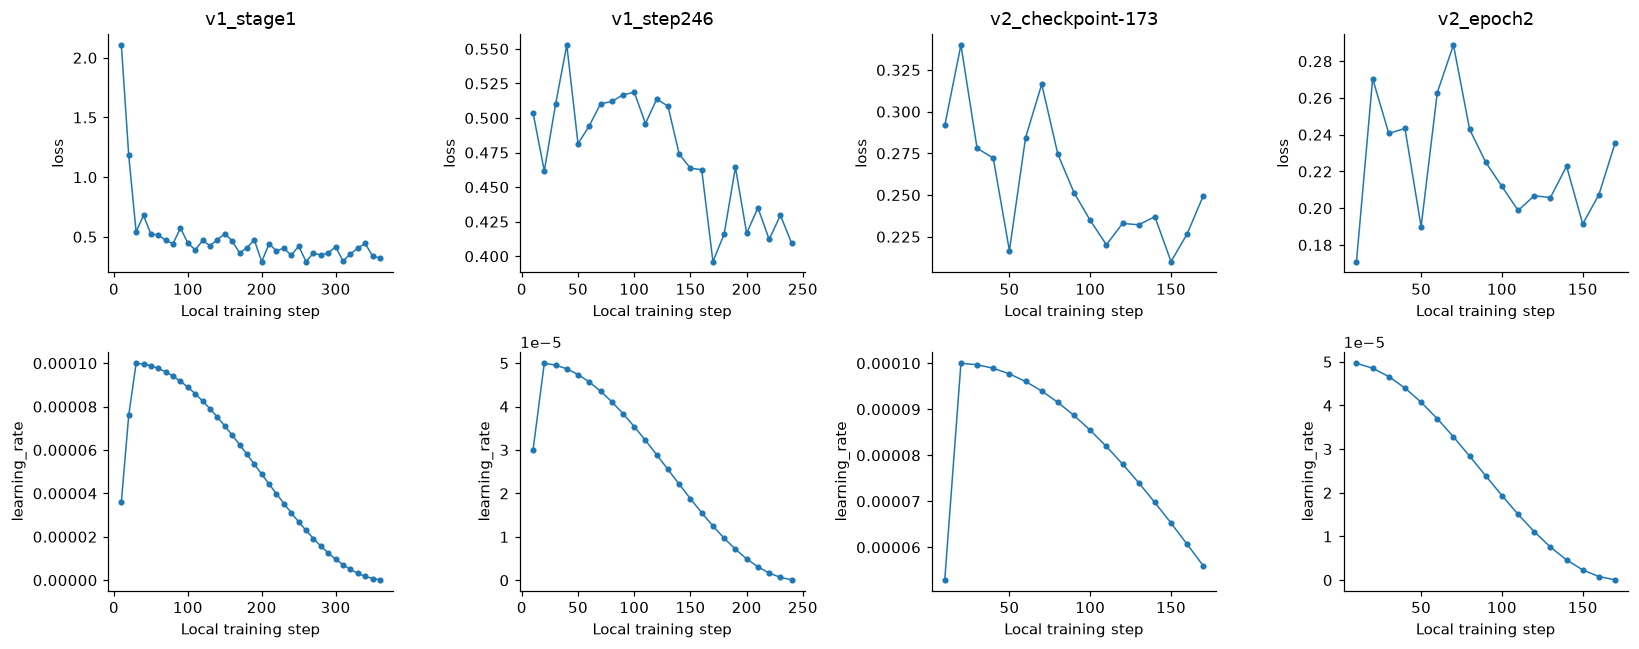

In [5]:
fig, axes = plt.subplots(2,4,figsize=(15,6))
for col,m in enumerate(models):
    history = pd.DataFrame(m['state']['log_history'])
    for row,metric in enumerate(['loss','learning_rate']):
        points = history.dropna(subset=[metric])
        axes[row,col].plot(points['step'],points[metric], marker='.', linewidth=1)
        axes[row,col].set(title=m['name'] if row==0 else '', xlabel='Local training step', ylabel=metric)
fig.tight_layout(); plt.show()


## 5. Rank capacity: an explanation, not an accuracy result
All four saved adapters use rank 16. The chart below scales parameter count for the same target modules; ranks 4/8/32/64 have not been trained or evaluated here. Increasing rank increases capacity and cost, not guaranteed quality.

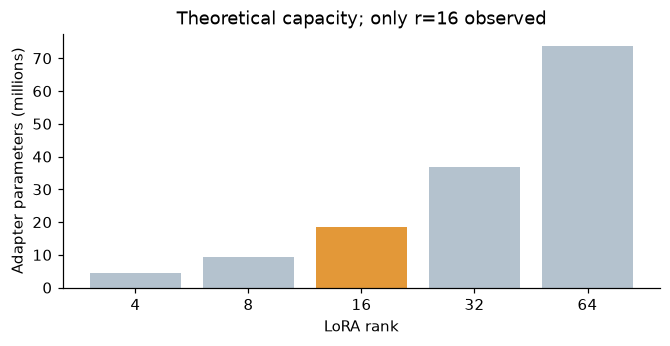

In [6]:
ranks = np.array([4,8,16,32,64])
counts = adapter * ranks / models[0]['config']['r']
fig, ax = plt.subplots(figsize=(7,3))
ax.bar(ranks.astype(str), counts/1e6, color=['#b4c2ce','#b4c2ce','#e39838','#b4c2ce','#b4c2ce'])
ax.set(xlabel='LoRA rank', ylabel='Adapter parameters (millions)', title='Theoretical capacity; only r=16 observed')
plt.show()


## 6. What training progress can we substantiate?
Validation AUC measures ranking quality. The validation-selected threshold is used in notebook 2. v1 has a different prompt from base/v2; use the labels as complete recipes.

,val_auc,threshold
run,,
base_v2prompt,0.59507,0.18011
v1_step246,0.73690,0.53510
v2_checkpoint-173,0.70705,0.22816
v2_epoch2,0.70884,0.18011


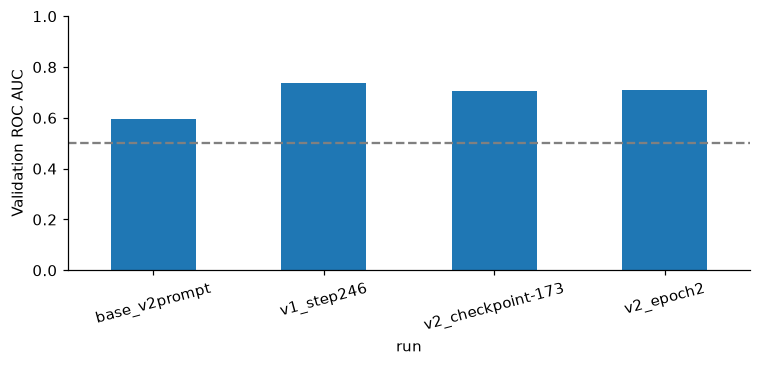

,comparison,status,interpretation / next step
0,"Base vs v2, same prompt",AVAILABLE,Other recipe factors still differ
1,"Base vs v1, identical input contract",NOT RUN,Run base using exact v1 contract on validation...
2,Controlled learning-rate sweep,NOT RUN,"Same initialization, split, rank, targets, ste..."
3,LoRA rank sweep,NOT RUN,All historical adapters have rank 16
4,v3 trained model evaluation,NOT RUN,Data preparation exists; trained checkpoint no...


In [7]:
table = score_table(B)
display(table[['val_auc','threshold']].round(5))
table['val_auc'].plot.bar(figsize=(8,3), ylim=(0,1), ylabel='Validation ROC AUC', rot=15)
plt.axhline(.5, color='gray', linestyle='--'); plt.show()
display(pd.DataFrame([
 ['Base vs v2, same prompt', 'AVAILABLE', 'Other recipe factors still differ'],
 ['Base vs v1, identical input contract', 'NOT RUN', 'Run base using exact v1 contract on validation first'],
 ['Controlled learning-rate sweep', 'NOT RUN', 'Same initialization, split, rank, targets, steps and seeds'],
 ['LoRA rank sweep', 'NOT RUN', 'All historical adapters have rank 16'],
 ['v3 trained model evaluation', 'NOT RUN', 'Data preparation exists; trained checkpoint not found']
], columns=['comparison','status','interpretation / next step']))


## 7. Panel explanation and source trail
“I trained small adapters on a frozen pretrained model, investigated an input-contract failure, and evaluated multiple training recipes. The newest recipe did not outperform v1 on the saved validation/test ranking metric. A controlled learning-rate or rank experiment is still needed to explain individual causes.”

The bundle contains original records/configurations and extracted tensor headers, with source hashes. Header hashes validate parameter metadata, not weight values. These are snapshots taken for this presentation; historical benchmark files do not establish a cryptographic link to the exact weights/code used at run time.

In [8]:
display(provenance(B))

,role,source,sha256,bytes
0,prior audit,D:\university\Resesarch\J26-SE-334\vision_orac...,dd4058fee921244cb5c3305d881946c6672b122247b974...,15421
1,tensor header (not weight content),D:\university\Resesarch\J26-SE-334\vision_orac...,7c0fed2cf13bde1906b514199f0e352183b949d24cce47...,73808
2,tensor header (not weight content),D:\university\Resesarch\J26-SE-334\vision_orac...,7692718763e900aed935798025815d45789769dbcef806...,5744
3,base architecture,D:\university\Resesarch\J26-SE-334\vision_orac...,422adefa19e62dd175961cec85bc0400344fe5bf9b22bd...,1196
4,tensor header (not weight content),D:\university\Resesarch\results\c3_lora_clean_...,120104a723728c3e7306f9bcbd77add2528563b72eb52a...,57912
5,v1_stage1 adapter config,D:\university\Resesarch\results\c3_lora_clean_...,c4ab6e9fb369c2e70991f5d061a5d4553616ef1799b756...,1264
6,v1_stage1 training state,D:\university\Resesarch\results\c3_lora_clean_...,20d81217abd6342913df6768d15cd498cc80c4f85027ee...,7953
7,tensor header (not weight content),D:\university\Resesarch\J26-SE-334\vision_orac...,120104a723728c3e7306f9bcbd77add2528563b72eb52a...,57912
8,v1_step246 adapter config,D:\university\Resesarch\J26-SE-334\vision_orac...,5efef80882bcdbe9ca4240cd0d2451d253e1734021464a...,1264
9,v1_step246 training state,D:\university\Resesarch\J26-SE-334\vision_orac...,8288d3fdfcab764a6e31443a6be686335d46ab60773261...,5666
